# Part 1 — Data Preparation
**Beyond Credit Scores: Discovering Borrower Risk Profiles and Early Warning Patterns for Loan Default**
DSAI 4102 Applied Data Mining · Group 1 · Jamal Ejaz (60301792)

This notebook turns the raw Lending Club file (2.26M loans, 151 columns) into one clean, leakage-free table that the
rest of the group builds on.

**Outputs**
- `data/processed/loans_clean.parquet`: the clean dataset
- `data/processed/feature_sets.json`: which columns to use for what (so the whole group uses the same ones)
- `data/processed/dropped_columns.csv`: every column left out, and why
- `data/processed/prep_funnel.csv`: how many loans survive each step
- `figures/01_*.png`: the exploratory figures

## 0. Setup

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The notebook lives in notebooks/, so the project folder is one level up.
# (If it's run from the project folder itself, use that folder.)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_FILE = ROOT / "data" / "raw" / "accepted_2007_to_2018Q4.csv"
OUT_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Every value I might have to justify is set here, in one place.
# last issue month in the file: a loan must have finished by then
DATA_END = pd.Timestamp("2018-12-01")
# cap extreme values at the 99.5th percentile (row kept, only the tail trimmed)
CAP_QUANTILE = 0.995
# loan purposes under 1% of loans are grouped into "other"
RARE_PURPOSE = 0.01
# shared seed for the whole group
RANDOM_STATE = 42

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)


def save(fig, name):
    # every figure goes to figures/ at high resolution, ready for the slides and the report
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")


print("Raw file found:", RAW_FILE.exists())

Raw file found: True


## 1. Choose the columns: leakage control
I keep only what Lending Club knew **on the day it approved the loan**. Everything I leave out is written to
`dropped_columns.csv` with the reason.

In [2]:
all_columns = pd.read_csv(RAW_FILE, nrows=0).columns.tolist()
print(len(all_columns), "columns in the raw file")

# What I keep, grouped by what it describes.
KEEP = {
    "id, outcome, date": ["id", "loan_status", "issue_d"],
    "Lending Club's own risk score": ["grade", "sub_grade", "int_rate"],
    "the loan": ["loan_amnt", "term", "installment", "purpose"],
    "the borrower": [
        "emp_length",
        "home_ownership",
        "annual_inc",
        "verification_status",
        "application_type",
    ],
    "credit report at application": [
        "dti",
        "fico_range_low",
        "fico_range_high",
        "earliest_cr_line",
        "delinq_2yrs",
        "inq_last_6mths",
        "mths_since_last_delinq",
        "open_acc",
        "pub_rec",
        "revol_bal",
        "revol_util",
        "total_acc",
        "mort_acc",
        "acc_open_past_24mths",
    ],
}
keep_cols = [c for group in KEEP.values() for c in group]
# grade / int_rate are known at approval, so they're not leakage. I keep them to compare against later,
# but they will NOT be used to build the profiles (see section 8).
print(len(keep_cols), "columns kept")

151 columns in the raw file
29 columns kept


In [3]:
# Columns recorded AFTER the loan was issued. If I kept these, the outcome would leak into the inputs.
# Example: recoveries > 0 only ever happens after a charge-off, so any model would "predict" default
# perfectly from it and learn nothing useful for a new applicant.
POST_LOAN = [
    "pymnt_plan",
    "out_prncp",
    "out_prncp_inv",
    "total_pymnt",
    "total_pymnt_inv",
    "total_rec_prncp",
    "total_rec_int",
    "total_rec_late_fee",
    "recoveries",
    "collection_recovery_fee",
    "last_pymnt_d",
    "last_pymnt_amnt",
    "next_pymnt_d",
    "last_credit_pull_d",
    "last_fico_range_high",
    "last_fico_range_low",
    "hardship_flag",
    "hardship_type",
    "hardship_reason",
    "hardship_status",
    "deferral_term",
    "hardship_amount",
    "hardship_start_date",
    "hardship_end_date",
    "payment_plan_start_date",
    "hardship_length",
    "hardship_dpd",
    "hardship_loan_status",
    "orig_projected_additional_accrued_interest",
    "hardship_payoff_balance_amount",
    "hardship_last_payment_amount",
    "debt_settlement_flag",
    "debt_settlement_flag_date",
    "settlement_status",
    "settlement_date",
    "settlement_amount",
    "settlement_percentage",
    "settlement_term",
]
# Second-applicant fields. I keep individual applications only (section 5), so these are always empty.
JOINT = [
    "annual_inc_joint",
    "dti_joint",
    "verification_status_joint",
    "revol_bal_joint",
] + [c for c in all_columns if c.startswith("sec_app_")]
# IDs, free text and admin fields: no information about the borrower's risk.
ADMIN_TEXT = [
    "member_id",
    "url",
    "desc",
    "emp_title",
    "title",
    "zip_code",
    "addr_state",
    "policy_code",
    "initial_list_status",
    "disbursement_method",
    "funded_amnt",
    "funded_amnt_inv",
]


def why_dropped(col):
    if col in POST_LOAN:
        return "recorded after the loan was issued (leakage)"
    if col in JOINT:
        return "joint-application field (individual loans only)"
    if col in ADMIN_TEXT:
        return "identifier, free text or admin field"
    # The rest are extra credit-bureau details: many are empty for pre-2012 loans, and most repeat
    # something I already keep (e.g. bc_util and percent_bc_gt_75 both measure utilisation, like revol_util).
    return "extra credit-bureau detail, not needed"


dropped = pd.DataFrame({"column": [c for c in all_columns if c not in keep_cols]})
dropped["reason"] = dropped["column"].map(why_dropped)
dropped.to_csv(OUT_DIR / "dropped_columns.csv", index=False)
dropped["reason"].value_counts()

reason
extra credit-bureau detail, not needed             56
recorded after the loan was issued (leakage)       38
joint-application field (individual loans only)    16
identifier, free text or admin field               12
Name: count, dtype: int64

## 2. Load the data

In [4]:
raw = pd.read_csv(RAW_FILE, usecols=keep_cols, low_memory=False)

# The last rows of the file are summary text ("Total amount funded..."), not loans. They have no loan amount.
raw = raw[raw["loan_amnt"].notna()].copy()
raw["id"] = raw["id"].astype("int64")

funnel = {"Raw loans": len(raw)}  # I log the row count after every step, for the report
print(f"{len(raw):,} loans loaded")

2,260,668 loans loaded


## 3. Define the target: did the loan default?

In [5]:
raw["loan_status"].value_counts()

loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
Name: count, dtype: int64

In [6]:
# Fully Paid = 0, Charged Off / Default = 1.
# Current, Late and In Grace loans are dropped: they haven't finished, so I can't label them yet.
# Calling "Current" a 0 would be wrong, because some of those loans will still default.
# "Does not meet the credit policy" loans were approved under older rules, so they're left out too.
TARGET = {"Fully Paid": 0, "Charged Off": 1, "Default": 1}
df = raw[raw["loan_status"].isin(TARGET)].copy()
df["default"] = df["loan_status"].map(TARGET)

funnel["Finished loans (paid off or defaulted)"] = len(df)
print(f"{len(df):,} finished loans, default rate {df['default'].mean():.1%}")

1,345,350 finished loans, default rate 20.0%


## 4. Convert text to numbers and dates

In [7]:
df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y")  # "Dec-2015"
# first credit line opened
df["earliest_cr_line"] = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y")
df["issue_year"] = df["issue_d"].dt.year
# " 36 months" -> 36
df["term_months"] = df["term"].str.extract(r"(\d+)")[0].astype(int)

# "10+ years" -> 10, "< 1 year" -> 0. Missing stays missing for now (filled in section 9).
df["emp_length"] = (
    df["emp_length"]
    .str.replace("< 1", "0", regex=False)
    .str.extract(r"(\d+)")[0]
    .astype(float)
)

## 5. Keep only loans that had time to finish
This is the most important cleaning decision in the project.

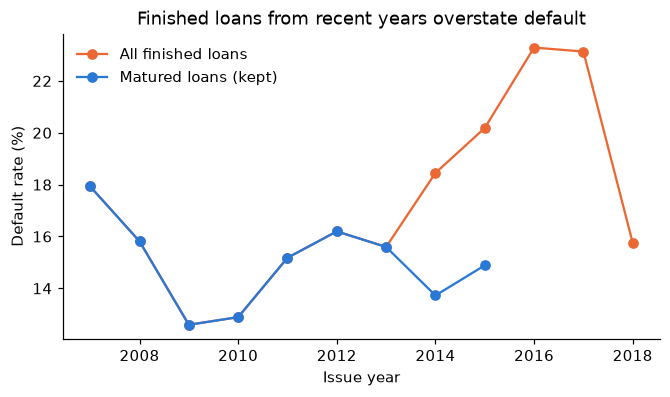

673,553 loans kept, issued 2007-2015


In [8]:
# The file stops in Dec 2018. A 60-month loan issued in 2017 cannot be fully paid by then, so the only 2017
# loans that are already "finished" are mostly the ones that went wrong early. Keeping them would make
# default look far more common than it is. So I keep a loan only if its full term ended by Dec 2018:
# in practice, 36-month loans issued up to 2015 and 60-month loans issued up to 2013.
months_until_end = (DATA_END.year - df["issue_d"].dt.year) * 12 + (
    DATA_END.month - df["issue_d"].dt.month
)
df["matured"] = months_until_end >= df["term_months"]

rate_all = df.groupby("issue_year")["default"].mean() * 100
rate_kept = df[df["matured"]].groupby("issue_year")["default"].mean() * 100

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(
    rate_all.index,
    rate_all.values,
    marker="o",
    color=ORANGE,
    label="All finished loans",
)
ax.plot(
    rate_kept.index,
    rate_kept.values,
    marker="o",
    color=BLUE,
    label="Matured loans (kept)",
)
ax.set(
    title="Finished loans from recent years overstate default",
    xlabel="Issue year",
    ylabel="Default rate (%)",
)
ax.legend(frameon=False)
save(fig, "01_default_rate_by_issue_year.png")
plt.show()
# How I read this: 2016-2017 loans look like ~23% default, against ~15% for loans that ran their full term.
# That gap is the bias I'm removing. 2018 drops back down because the only 2018 loans already finished
# are early pay-offs - the same bias in the other direction.

df = df[df["matured"]].copy()
funnel["Matured loans (full term ended by Dec 2018)"] = len(df)
print(
    f"{len(df):,} loans kept, issued {df['issue_year'].min()}-{df['issue_year'].max()}"
)

## 6. Scope and sanity checks

In [9]:
# Joint applications report combined income and DTI in separate columns, so they aren't comparable
# with individual loans row for row. They're a tiny share of this cohort anyway.
df = df[df["application_type"] == "Individual"].copy()
funnel["Individual applications"] = len(df)

# Impossible values. On this cohort none turn up, but I keep the check so the pipeline is safe on new data.
bad = (
    (df["annual_inc"] <= 0)
    | df["dti"].isna()
    | (df["dti"] < 0)
    | (df["dti"] > 100)
    | df["fico_range_low"].isna()
    | df["earliest_cr_line"].isna()
)
print("Rows with impossible values:", int(bad.sum()))
df = df[~bad].copy()
funnel["After sanity checks"] = len(df)

Rows with impossible values: 0


## 7. Build features that describe the borrower's situation

In [10]:
# Raw amounts measure size, not risk: a $30k loan means something very different on a $40k salary
# than on a $200k one. Ratios put every borrower on the same footing.
df["loan_to_income"] = df["loan_amnt"] / df["annual_inc"]
# yearly repayments vs income
df["payment_to_income"] = df["installment"] * 12 / df["annual_inc"]
df["credit_history_years"] = (df["issue_d"] - df["earliest_cr_line"]).dt.days / 365.25
# income is very skewed; on a log scale distances make sense
df["log_annual_inc"] = np.log1p(df["annual_inc"])
# LC reports FICO as a 4-point range
df["fico_mean"] = (df["fico_range_low"] + df["fico_range_high"]) / 2

# mths_since_last_delinq is empty when the borrower has NEVER been delinquent,
# so "missing" here is information, not noise. I turn it into a yes/no flag instead of filling it.
df["has_delinq_history"] = (
    df["mths_since_last_delinq"].notna() | (df["delinq_2yrs"] > 0)
).astype(int)
df["has_public_record"] = (df["pub_rec"] > 0).astype(int)

# Tidy the categories: NONE / ANY add up to under 200 loans, too few to stand alone.
df["home_ownership"] = df["home_ownership"].replace({"NONE": "OTHER", "ANY": "OTHER"})
rare = df["purpose"].value_counts(normalize=True).loc[lambda s: s < RARE_PURPOSE].index
df["purpose"] = df["purpose"].replace(dict.fromkeys(rare, "other"))
print("Purposes grouped into 'other':", list(rare))

Purposes grouped into 'other': ['moving', 'vacation', 'house', 'wedding', 'renewable_energy', 'educational']


## 8. Decide which features are used for what

In [11]:
# The features the clustering (Part 2) uses: income, employment, debt burden, utilisation,
# credit-seeking, account mix, credit history and past problems.
CLUSTER_NUMERIC = [
    "log_annual_inc",
    "emp_length",
    "dti",
    "loan_to_income",
    "revol_util",
    "inq_last_6mths",
    "acc_open_past_24mths",
    "open_acc",
    "total_acc",
    "mort_acc",
    "credit_history_years",
    "delinq_2yrs",
    "has_delinq_history",
    "has_public_record",
]
CLUSTER_CATEGORICAL = [
    "home_ownership",
    "purpose",
    "verification_status",
    "term_months",
]

# Deliberately NOT in the clustering:
# - grade, sub_grade, int_rate, fico_mean: this is Lending Club's own credit score. Leaving it out lets
#   us test whether our profiles find risk the score misses - the "Beyond Credit Scores" in our title.
CREDIT_SCORE_COLS = ["grade", "sub_grade", "int_rate", "fico_mean"]
# - payment_to_income: it is ~0.97 correlated with loan_to_income (loan size would count twice), and the
#   instalment is calculated from the grade-based interest rate, so the credit score would sneak back in.
#   I keep it, with the raw amounts, only to describe the profiles.
DESCRIBE_ONLY = [
    "loan_amnt",
    "annual_inc",
    "installment",
    "payment_to_income",
    "revol_bal",
]
# - bc_util and percent_bc_gt_75 (not loaded): I tried them. bc_util correlates 0.79 with revol_util and
#   percent_bc_gt_75 correlates 0.83 with bc_util, so utilisation would have been counted three times
#   in the distance calculation.

## 9. Cap extreme values and fill small gaps

In [12]:
# K-Means works on distances, so a handful of $5M incomes would drag a whole cluster towards them.
# I cap rather than delete: the borrower stays in, only the extreme value is pulled back to the 99.5th percentile.
TO_CAP = [
    "annual_inc",
    "revol_bal",
    "dti",
    "loan_to_income",
    "payment_to_income",
    "revol_util",
    "open_acc",
    "total_acc",
    "mort_acc",
    "credit_history_years",
    "inq_last_6mths",
    "delinq_2yrs",
    "acc_open_past_24mths",
]
caps = df[TO_CAP].quantile(CAP_QUANTILE)
df[TO_CAP] = df[TO_CAP].clip(upper=caps, axis=1)
df["log_annual_inc"] = np.log1p(df["annual_inc"])  # recompute from the capped income
caps.round(2).to_frame("cap at 99.5th percentile")

,cap at 99.5th percentile
annual_inc,304000.00
revol_bal,124989.78
dti,38.26
loan_to_income,0.50
payment_to_income,0.20
revol_util,99.50
open_acc,31.00
total_acc,63.00
mort_acc,9.00
credit_history_years,42.92


In [13]:
print("Share missing before filling:")
print(df[CLUSTER_NUMERIC].isna().mean().loc[lambda s: s > 0].round(3).to_string())

# mort_acc and acc_open_past_24mths are blank for every loan issued 2007-2011 (and 14% of 2012 loans):
# Lending Club hadn't started reporting them yet. That's ~7% of all loans, filled here with the median.
# Because these gaps follow the issue year rather than chance, those older borrowers get an "average"
# value for both, so they can never count as "no mortgage" or "many new accounts" in Part 1b's rules.
# I report this as a limitation. emp_length (~6%) and revol_util (0.1%) are scattered gaps, where a
# median fill is fine.
medians = df[CLUSTER_NUMERIC].median()
df[CLUSTER_NUMERIC] = df[CLUSTER_NUMERIC].fillna(medians)

funnel["Final clean dataset"] = len(df)

Share missing before filling:
emp_length              0.056
revol_util              0.001
acc_open_past_24mths    0.070
mort_acc                0.070


## 10. Explore the clean data
### 10.1 The benchmark: default rate by Lending Club grade

673,314 loans · 99,742 defaults · base default rate 14.8%


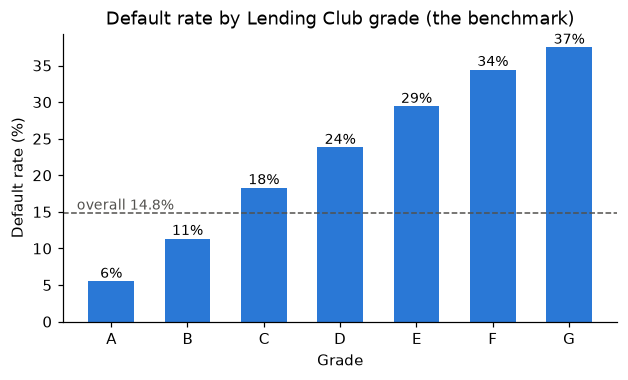

In [14]:
base_rate = df["default"].mean()
print(
    f"{len(df):,} loans · {df['default'].sum():,} defaults · base default rate {base_rate:.1%}"
)

by_grade = df.groupby("grade")["default"].mean() * 100
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.bar(by_grade.index, by_grade.values, color=BLUE, width=0.6)
ax.axhline(base_rate * 100, color=GREY, linestyle="--", linewidth=1)
ax.text(
    -0.45, base_rate * 100 + 0.5, f"overall {base_rate:.1%}", color=GREY, fontsize=9
)
for x, v in enumerate(by_grade.values):
    ax.text(x, v + 0.5, f"{v:.0f}%", ha="center", fontsize=9)
ax.set(
    title="Default rate by Lending Club grade (the benchmark)",
    xlabel="Grade",
    ylabel="Default rate (%)",
)
save(fig, "01_default_rate_by_grade.png")
plt.show()
# Grade already separates risk well (A ~6% -> G ~37%). Our profiles only add value if they show
# differences WITHIN a grade - that's what Part 4 tests.

### 10.2 Do the risk factors from the proposal line up with default?

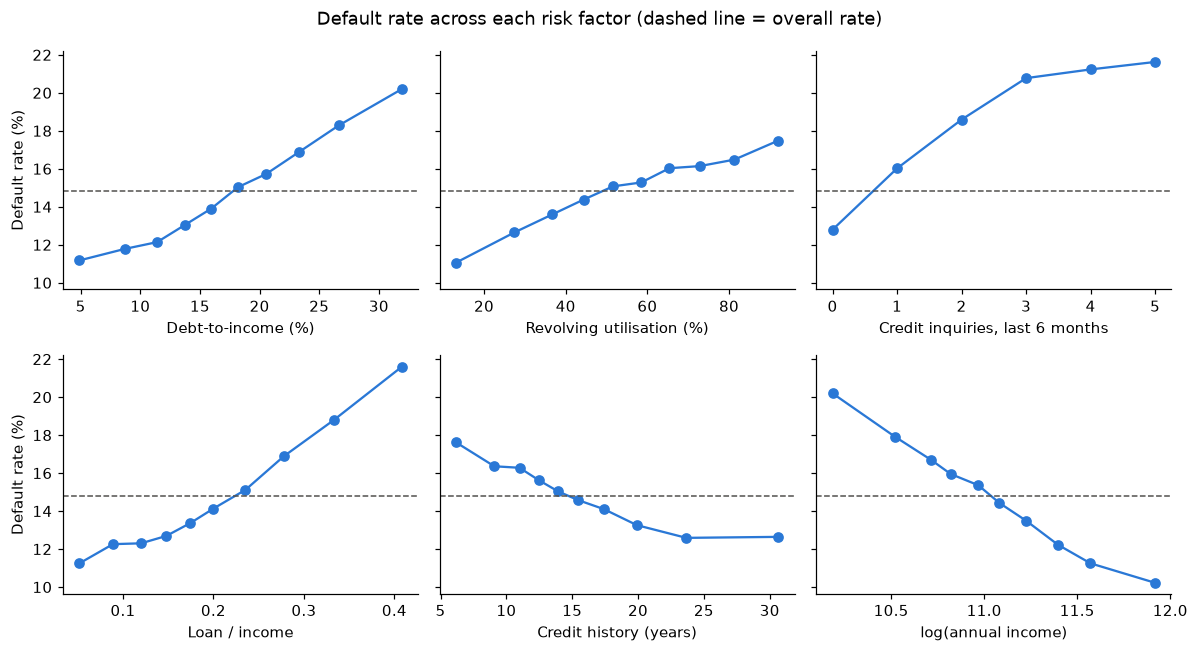

In [15]:
def default_rate_by_bin(col):
    # counts (like inquiries) get one point per value; continuous features get 10 equal-sized groups
    groups = (
        df[col] if df[col].nunique() <= 10 else pd.qcut(df[col], 10, duplicates="drop")
    )
    out = df.groupby(groups, observed=True).agg(
        x=(col, "median"), rate=("default", "mean"), n=("default", "size")
    )
    # ignore tiny groups so one odd value doesn't show as a spike
    return out[out["n"] >= 200]


panels = {
    "dti": "Debt-to-income (%)",
    "revol_util": "Revolving utilisation (%)",
    "inq_last_6mths": "Credit inquiries, last 6 months",
    "loan_to_income": "Loan / income",
    "credit_history_years": "Credit history (years)",
    "log_annual_inc": "log(annual income)",
}

fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharey=True)
for ax, (col, label) in zip(axes.ravel(), panels.items()):
    r = default_rate_by_bin(col)
    ax.plot(r["x"], r["rate"] * 100, marker="o", color=BLUE)
    ax.axhline(base_rate * 100, color=GREY, linestyle="--", linewidth=1)
    ax.set_xlabel(label)
for ax in axes[:, 0]:
    ax.set_ylabel("Default rate (%)")
fig.suptitle("Default rate across each risk factor (dashed line = overall rate)")
fig.tight_layout()
save(fig, "01_default_rate_by_feature.png")
plt.show()
# All six move the way the proposal expected: more debt, higher utilisation and more recent credit
# applications go with more default; higher income and a longer credit history go with less.

### 10.3 Default rate by category

In [16]:
for col in CLUSTER_CATEGORICAL:
    table = (
        df.groupby(col)["default"]
        .agg(default_rate="mean", loans="size")
        .sort_values("default_rate")
    )
    table["default_rate"] = (table["default_rate"] * 100).round(1)
    print(f"\n{table.to_string()}")
# One result that looks backwards: "Verified" income defaults MORE than "Not Verified".
# Lending Club chose which applicants to verify, and it verified the ones it already saw as riskier,
# so verification marks suspected risk rather than causing it.


                default_rate   loans
home_ownership                      
MORTGAGE                12.6  320645
OWN                     15.5   66789
RENT                    17.1  285689
OTHER                   17.8     191

                    default_rate   loans
purpose                                 
car                         11.8    7786
credit_card                 12.2  158998
home_improvement            13.1   39080
major_purchase              13.1   14074
debt_consolidation          15.6  385784
other                       17.0   51716
medical                     17.3    7243
small_business              24.4    8633

                     default_rate   loans
verification_status                      
Not Verified                 11.7  218217
Source Verified              14.9  231878
Verified                     17.8  223219

             default_rate   loans
term_months                      
36                   13.9  618345
60                   25.2   54969


### 10.4 How the clustering features relate to each other

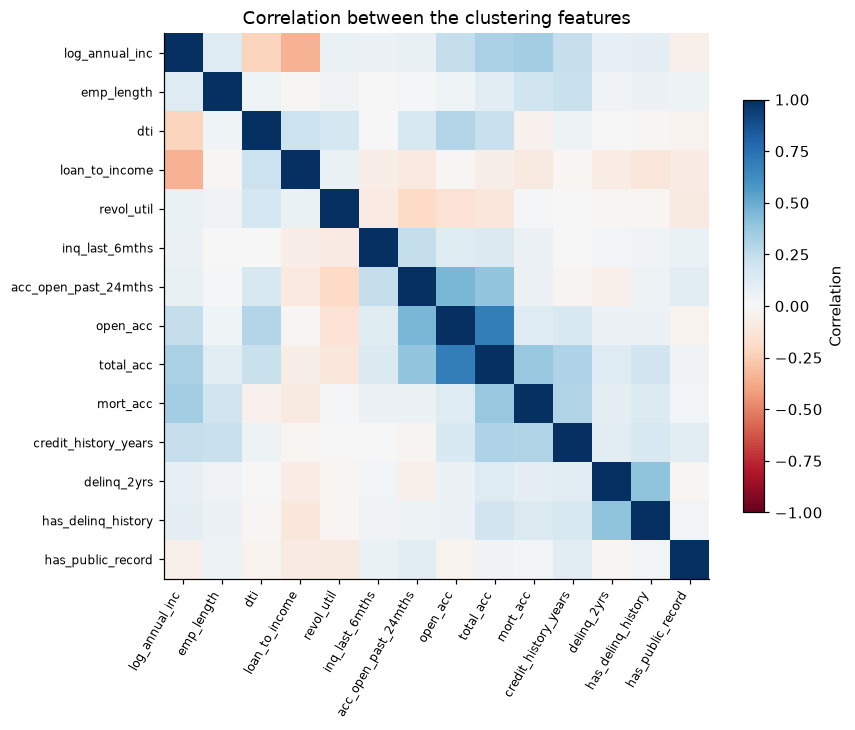

Strongest pairs:
 open_acc              total_acc             0.69
acc_open_past_24mths  open_acc              0.46
delinq_2yrs           has_delinq_history    0.40
acc_open_past_24mths  total_acc             0.39
total_acc             mort_acc              0.38


In [17]:
# Two features that say the same thing count twice in a distance calculation, so I check for near-duplicates.
corr = df[CLUSTER_NUMERIC].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.75, label="Correlation")
ax.set_title("Correlation between the clustering features")
save(fig, "01_feature_correlation.png")
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(
    "Strongest pairs:\n",
    pairs.abs().sort_values(ascending=False).head(5).round(2).to_string(),
)
# No pair is near-duplicate (all well under 0.8). open_acc vs total_acc is the strongest, but one counts
# accounts open now and the other every account ever opened, so both stay.

## 11. Save the outputs for the group

In [18]:
columns_out = (
    ["id", "issue_d", "issue_year", "default"]
    + CREDIT_SCORE_COLS
    + CLUSTER_NUMERIC
    + CLUSTER_CATEGORICAL
    + DESCRIBE_ONLY
)
clean = df[columns_out].reset_index(drop=True)
clean.to_parquet(OUT_DIR / "loans_clean.parquet", index=False)

# One shared definition of the feature groups, so nobody in the group retypes column names.
feature_sets = {
    "data_file": "loans_clean.parquet",
    "target": "default",
    "id": "id",
    "base_default_rate": round(float(base_rate), 4),
    "random_state": RANDOM_STATE,
    "cluster_numeric": CLUSTER_NUMERIC,
    "cluster_categorical": CLUSTER_CATEGORICAL,
    "credit_score_cols": CREDIT_SCORE_COLS,
    "describe_only": DESCRIBE_ONLY,
}
(OUT_DIR / "feature_sets.json").write_text(json.dumps(feature_sets, indent=2))

funnel_table = pd.Series(funnel, name="loans").to_frame()
funnel_table.to_csv(OUT_DIR / "prep_funnel.csv")
print(f"Saved {clean.shape[0]:,} loans x {clean.shape[1]} columns")
funnel_table

Saved 673,314 loans x 31 columns


,loans
Raw loans,2260668
Finished loans (paid off or defaulted),1345350
Matured loans (full term ended by Dec 2018),673553
Individual applications,673314
After sanity checks,673314
Final clean dataset,673314
